In [1]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


In [3]:
%pip install -q ultralytics onnx

In [4]:
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt

from ultralytics import YOLO
from google.colab import files

print("All libraries imported successfully!")

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Select GPU runtime.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
All libraries imported successfully!
PyTorch Version: 2.14.1+cpu
CUDA Available: False
GPU not available. Select GPU runtime.


In [5]:
# Load pretrained YOLOv8 Nano model

model = YOLO("yolov8n.pt")

print("YOLOv8 Model Loaded Successfully!")

print("Model Name: YOLOv8 Nano")
print("Model Task:", model.task)

YOLOv8 Model Loaded Successfully!
Model Name: YOLOv8 Nano
Model Task: detect


In [6]:
# Load pretrained YOLOv8 Nano model

model = YOLO("yolov8n.pt")

print("YOLOv8 Model Loaded Successfully!")

print("Model Name: YOLOv8 Nano")
print("Model Task:", model.task)

YOLOv8 Model Loaded Successfully!
Model Name: YOLOv8 Nano
Model Task: detect


In [7]:
# COCO class IDs
fruit_classes = {
    46: "banana",
    47: "apple",
    49: "orange"
}

print("Fruit Classes Supported:")

for class_id, fruit in fruit_classes.items():
    print(class_id, ":", model.names[class_id])

Fruit Classes Supported:
46 : banana
47 : apple
49 : orange


In [9]:
uploaded = files.upload()

image_path = next(iter(uploaded.keys()))

print("Uploaded Image:", image_path)

Saving 3a3d4b04d70cc293fadf195b4e1a7bcb.jpg to 3a3d4b04d70cc293fadf195b4e1a7bcb.jpg
Uploaded Image: 3a3d4b04d70cc293fadf195b4e1a7bcb.jpg



image 1/1 /content/3a3d4b04d70cc293fadf195b4e1a7bcb.jpg: 448x640 1 banana, 3 apples, 3 oranges, 298.4ms
Speed: 22.2ms preprocess, 298.4ms inference, 29.6ms postprocess per image at shape (1, 3, 448, 640)


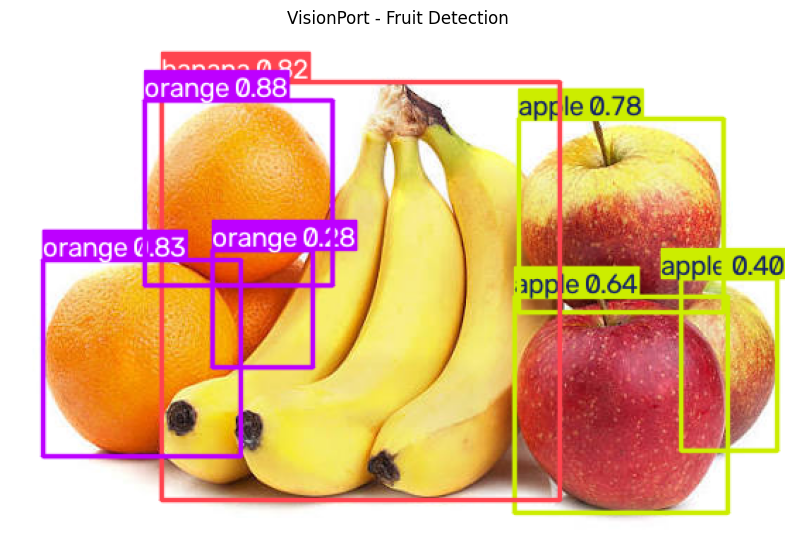

In [10]:
# Run YOLOv8 inference

results = model.predict(
    source=image_path,
    classes=[46, 47, 49],
    conf=0.25,
    device=0 if torch.cuda.is_available() else "cpu"
)

# Display detected fruits

result_image = results[0].plot()

plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("VisionPort - Fruit Detection")
plt.show()

In [11]:
result = results[0]

print("FRUIT DETECTION RESULTS")
print("-----------------------")

if result.boxes is not None:

    for box in result.boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])

        fruit_name = model.names[class_id]

        print(
            f"Fruit: {fruit_name} | "
            f"Confidence: {confidence:.2f}"
        )

    print("\nTotal Fruits Detected:", len(result.boxes))

else:
    print("No fruits detected.")

FRUIT DETECTION RESULTS
-----------------------
Fruit: orange | Confidence: 0.88
Fruit: orange | Confidence: 0.83
Fruit: banana | Confidence: 0.82
Fruit: apple | Confidence: 0.78
Fruit: apple | Confidence: 0.64
Fruit: apple | Confidence: 0.40
Fruit: orange | Confidence: 0.28

Total Fruits Detected: 7
